<center>

$\Huge \textbf{Universidad Tecmilenio}$  
<p align="center">
  <img src="https://sic.cultura.gob.mx/images/135155" alt="Tecmilenio" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Actividad 04 - Modelos PreEntrenados}$  

$\Large \textit{Gestión de Proyectos de IA}$    

\begin{array}{rl}
\textbf{Docente:} & Eliskar Roger Altamirano Pariente \\[6pt]
\textbf{Alumno:} & Gabriel Ramírez Cázares \\[6pt]
\textbf{Fecha de entrega:} & 11/10/2026
\end{array}

</center>

# Benchmark de Modelos Preentrenados de Hugging Face para Ciberseguridad
**Caso de uso:** Detección de Phishing en Texto (Correos Electrónicos y URLs).

**Objetivo:** Comparar tres modelos preentrenados (`facebook/bart-large-mnli`, `MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli` y `joeddav/xlm-roberta-large-xnli`) utilizando métricas estándar (Accuracy, Precision, Recall, F1-score) y latencia de inferencia sobre un entorno de Google Colab con GPU.

### 1.0 Autenticar en Hugging Face

In [1]:
# ==========================================
# Autenticación en Hugging Face Hub
# ==========================================

# Instalar la librería si no viene preinstalada
!pip install -q huggingface_hub

# Cargar el token de forma segura desde los secretos de Colab
from google.colab import userdata
from huggingface_hub import login

try:
    hf_token = userdata.get('HF_TOKEN')
    login(token=hf_token)
    print("¡Autenticación exitosa con Hugging Face!")
except Exception as e:
    print("No se encontró el secreto HF_TOKEN. Hay que configurarlo en el panel lateral izquierdo (🔑).")

¡Autenticación exitosa con Hugging Face!


### 2.0 Cargar y Preparar el Dataset de Ciberseguridad (Phising)

In [2]:
# ==========================================
# Carga y Preparación del Dataset
# ==========================================

from datasets import load_dataset
import pandas as pd

print("[INFO] Descargando subconjunto de prueba del dataset de phishing...")
# Cargamos un segmento manejable para prototipado rápido en Colab (150 muestras)
dataset = load_dataset("zefang-liu/phishing-email-dataset", split="train[:150]")

# Convertir a DataFrame de Pandas para manipulación cómoda
df_data = dataset.to_pandas()

# Estandarizar columnas al formato estándar del script ('text' y 'label')
# El dataset utiliza 'Email Text' y 'Email Type' ("Safe Email" / "Phishing Email")
df_data = df_data.rename(columns={"Email Text": "text", "Email Type": "label_str"})
df_data["label"] = df_data["label_str"].apply(lambda x: 1 if "Phishing" in str(x) else 0)

# Limpiar posibles valores nulos
df_data = df_data.dropna(subset=["text"])

print(f"[INFO] Dataset cargado con éxito. Total de muestras de evaluación: {len(df_data)}")
display(df_data[["text", "label"]].head(3))

[INFO] Descargando subconjunto de prueba del dataset de phishing...


README.md:   0%|          | 0.00/616 [00:00<?, ?B/s]

Phishing_Email.csv: reconstructing file:   0%|          |  0.00B / 52.0MB            

Phishing_Email.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/18650 [00:00<?, ? examples/s]

[INFO] Dataset cargado con éxito. Total de muestras de evaluación: 149


,text,label
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",0
1,the other side of * galicismos * * galicismo *...,0
2,re : equistar deal tickets are you still avail...,0


### 3.0 Dataset Análisis Exploratorio

/tmp/ipykernel_4480/22754517.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_data, x="label_name", palette=["#e74c3c", "#2ecc71"])


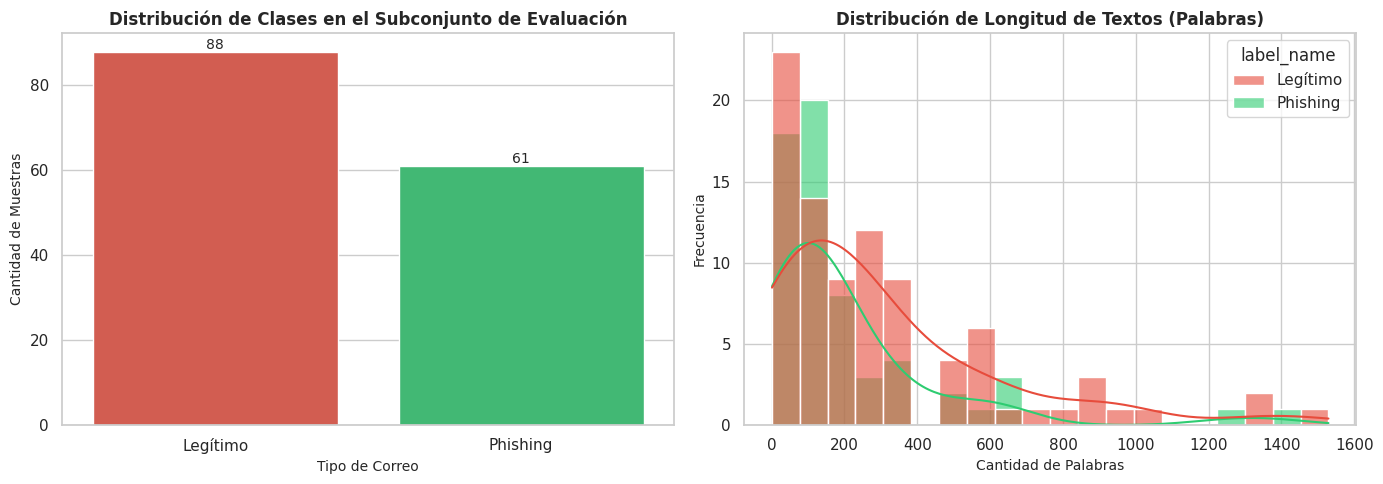


       EJEMPLOS DE REGISTROS EN EL DATASET        


,text,label_name
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Legítimo
1,the other side of * galicismos * * galicismo *...,Legítimo
2,re : equistar deal tickets are you still avail...,Legítimo
3,\nHello I am your hot lil horny toy.\n I am...,Phishing
4,software at incredibly low prices ( 86 % lower...,Phishing
5,global risk management operations sally congra...,Legítimo


In [3]:
# ==========================================
# Análisis Exploratorio de Datos (EDA) y Visualización
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Mapear etiquetas numéricas a texto descriptivo para mayor claridad visual
df_data["label_name"] = df_data["label"].map({1: "Phishing", 0: "Legítimo"})

# Gráfico 1: Distribución de Clases (Balance del subconjunto)
plt.subplot(1, 2, 1)
ax = sns.countplot(data=df_data, x="label_name", palette=["#e74c3c", "#2ecc71"])
plt.title("Distribución de Clases en el Subconjunto de Evaluación", fontsize=12, fontweight="bold")
plt.xlabel("Tipo de Correo", fontsize=10)
plt.ylabel("Cantidad de Muestras", fontsize=10)

# Añadir etiquetas de conteo sobre cada barra
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)

# Gráfico 2: Distribución de la longitud de los textos (número de palabras por categoría)
plt.subplot(1, 2, 2)
df_data["word_count"] = df_data["text"].apply(lambda x: len(str(x).split()))
sns.histplot(data=df_data, x="word_count", hue="label_name", bins=20, kde=True, palette=["#e74c3c", "#2ecc71"], alpha=0.6)
plt.title("Distribución de Longitud de Textos (Palabras)", fontsize=12, fontweight="bold")
plt.xlabel("Cantidad de Palabras", fontsize=10)
plt.ylabel("Frecuencia", fontsize=10)

plt.tight_layout()
plt.show()

# Mostrar una tabla resumen con algunas muestras representativas del dataset
print("\n==================================================")
print("       EJEMPLOS DE REGISTROS EN EL DATASET        ")
print("==================================================")
display(df_data[["text", "label_name"]].head(6))

### 4.0 Verificar Hardware

In [4]:
# ==========================================
# Verificación de Aceleración por GPU y Entorno
# ==========================================
import torch

print(f"[INFO] PyTorch Versión: {torch.__version__}")
if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    print(f"[SUCCESS] GPU Detectada: {device_name}. Usando dispositivo CUDA.")
    DEVICE = 0
else:
    print("[WARNING] No se detectó GPU. La ejecución se realizará en CPU (puede ser lenta).")
    DEVICE = -1

[INFO] PyTorch Versión: 2.11.0+cu130
[SUCCESS] GPU Detectada: Tesla T4. Usando dispositivo CUDA.


### 5.0 Inicializar los tres modelos preentrenados

In [5]:
# ==========================================
# Carga de los 3 Modelos Preentrenados (Pipelines)
# ==========================================
from transformers import pipeline
import time

print("[INFO] Inicializando pipelines de Zero-Shot Classification en la GPU...")

# Diccionario con los 3 modelos seleccionados para ciberseguridad NLP
models_config = {
    "BART-Large": "facebook/bart-large-mnli",
    "DeBERTa-v3-Base": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
    "XLM-RoBERTa-Large": "joeddav/xlm-roberta-large-xnli"
}

pipelines = {}
for model_name, model_path in models_config.items():
    start_load = time.time()
    print(f" -> Cargando modelo: {model_name} ({model_path})...")
    pipelines[model_name] = pipeline(
        "zero-shot-classification",
        model=model_path,
        device=DEVICE
    )
    print(f"    [OK] {model_name} cargado en {time.time() - start_load:.2f} segundos.")

print("[SUCCESS] Todos los modelos han sido desplegados en memoria.")

[INFO] Inicializando pipelines de Zero-Shot Classification en la GPU...
 -> Cargando modelo: BART-Large (facebook/bart-large-mnli)...


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

    [OK] XLM-RoBERTa-Large cargado en 52.63 segundos.
[SUCCESS] Todos los modelos han sido desplegados en memoria.


### 6.0 Pipeline de Inferencia y Medidas de Latencia

In [6]:
# ==========================================
# Ejecución de Inferencia y Medición de Latencia
# ==========================================
import time
import numpy as np

candidate_labels = ["legitimate", "phishing"]
texts = df_data["text"].tolist()
true_labels = df_data["label"].tolist() # 0: legitimate, 1: phishing

evaluation_results = {}

for model_name, clf_pipeline in pipelines.items():
    print(f"\n[INFERENCIA] Procesando con {model_name}...")
    predictions = []
    latencies = []

    for text in texts:
        # Medición de latencia por inferencia individual
        start_time = time.time()

        # Ejecución del pipeline zero-shot
        output = clf_pipeline(text, candidate_labels=candidate_labels, hypothesis_template="Este texto es {}")

        end_time = time.time()
        latencies.append((end_time - start_time) * 1000) # Convertir a milisegundos (ms)

        # Extraer la etiqueta predicha con mayor score
        top_label = output["labels"][0] # 'phishing' o 'legitimate'
        pred_val = 1 if top_label == "phishing" else 0
        predictions.append(pred_val)

    evaluation_results[model_name] = {
        "predictions": predictions,
        "latencies_ms": latencies,
        "avg_latency_ms": np.mean(latencies),
        "p95_latency_ms": np.percentile(latencies, 95)
    }
    print(f" -> {model_name} finalizado. Latencia promedio: {evaluation_results[model_name]['avg_latency_ms']:.2f} ms/muestra.")


[INFERENCIA] Procesando con BART-Large...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


 -> BART-Large finalizado. Latencia promedio: 181.26 ms/muestra.

[INFERENCIA] Procesando con DeBERTa-v3-Base...
 -> DeBERTa-v3-Base finalizado. Latencia promedio: 88.25 ms/muestra.

[INFERENCIA] Procesando con XLM-RoBERTa-Large...
 -> XLM-RoBERTa-Large finalizado. Latencia promedio: 129.01 ms/muestra.


### 7.0 Cálculo de Métricas Estándar

In [7]:
# ==========================================
# Cálculo de Métricas de Rendimiento (Scikit-Learn)
# ==========================================
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import pandas as pd

metrics_summary = []

for model_name, res in evaluation_results.items():
    preds = res["predictions"]

    # Cálculo de métricas estándar
    acc = accuracy_score(true_labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(true_labels, preds, average="binary", zero_division=0)

    metrics_summary.append({
        "Model": model_name,
        "Accuracy": round(acc * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2),
        "Avg Latency (ms)": round(res["avg_latency_ms"], 2),
        "P95 Latency (ms)": round(res["p95_latency_ms"], 2)
    })

df_metrics = pd.DataFrame(metrics_summary)
print("[SUCCESS] Cálculo de métricas completado.")

[SUCCESS] Cálculo de métricas completado.


### 8.0 Generación de Tablas Comparativas y Visualización Gráfica

     TABLA COMPARATIVA DE MODELOS - CIBERSEGURIDAD


,Accuracy,Precision (%),Recall (%),F1-Score (%),Avg Latency (ms),P95 Latency (ms)
Model,,,,,,
BART-Large,51.68,26.09,9.84,14.29,181.26,484.95
DeBERTa-v3-Base,57.72,43.75,11.48,18.18,88.25,199.22
XLM-RoBERTa-Large,51.68,26.09,9.84,14.29,129.01,225.32


/tmp/ipykernel_4480/3475965252.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_metrics, x="Model", y="Avg Latency (ms)", ax=axes[1], palette="crest")


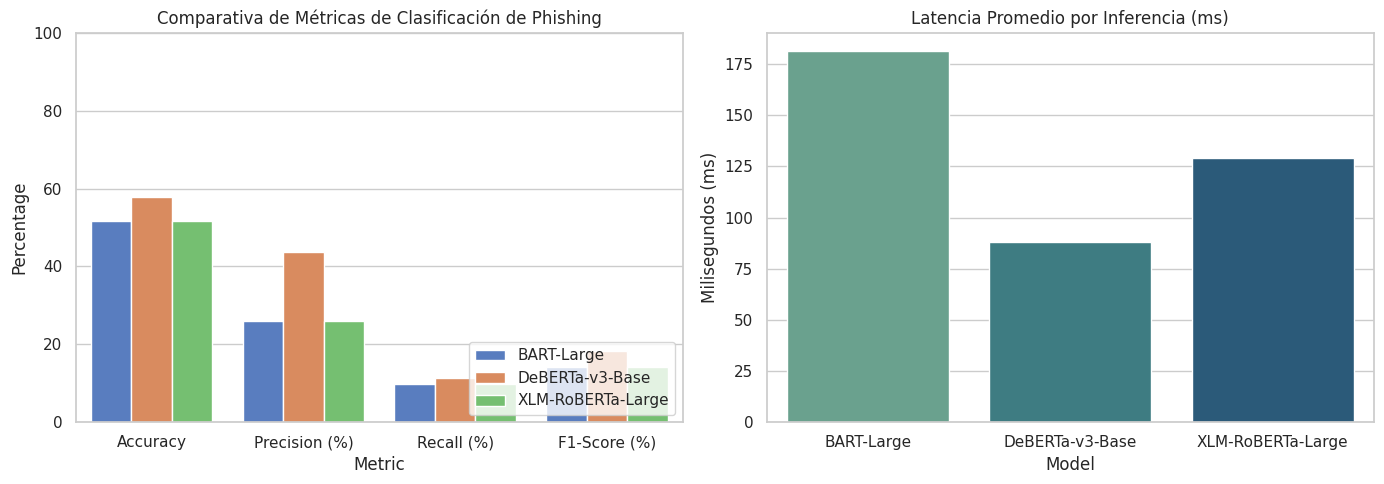

In [8]:
# ==========================================
# Tablas de Resumen y Gráficas Comparativas
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# Mostrar tabla ejecutiva formateada
print("==================================================")
print("     TABLA COMPARATIVA DE MODELOS - CIBERSEGURIDAD")
print("==================================================")
display(df_metrics.set_index("Model"))

# Gráfica comparativa de rendimiento (Métricas vs Latencia)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Métricas de Clasificación
df_melted = df_metrics.melt(id_vars="Model", value_vars=["Accuracy", "Precision (%)", "Recall (%)", "F1-Score (%)"],
                            var_name="Metric", value_name="Percentage")
sns.barplot(data=df_melted, x="Metric", y="Percentage", hue="Model", ax=axes[0], palette="muted")
axes[0].set_title("Comparativa de Métricas de Clasificación de Phishing")
axes[0].set_ylim(0, 100)
axes[0].legend(loc="lower right")

# Gráfica 2: Latencia Promedio de Inferencia
sns.barplot(data=df_metrics, x="Model", y="Avg Latency (ms)", ax=axes[1], palette="crest")
axes[1].set_title("Latencia Promedio por Inferencia (ms)")
axes[1].set_ylabel("Milisegundos (ms)")

plt.tight_layout()
plt.show()

### 9.0 Generar Archivo con las Dependencias Utilizadas

In [9]:
# ==========================================
# Definición y Creación de requirements.txt
# ==========================================
# Identificación de librerías utilizadas y versiones estables compatibles con Colab (GPU T4)

# ==========================================
# Generación Automatizada de requirements.txt
# ==========================================
import importlib.metadata

# Lista de librerías principales utilizadas en el notebook de ciberseguridad
libraries_to_check = [
    "torch",
    "transformers",
    "datasets",
    "scikit-learn",
    "pandas",
    "matplotlib",
    "seaborn",
    "huggingface_hub"
]

generated_requirements = []

print("[INFO] Extrayendo versiones activas del entorno de Google Colab...")
for lib in libraries_to_check:
    try:
        # Obtener la versión instalada actualmente en la sesión
        version = importlib.metadata.version(lib)
        requirement_line = f"{lib}=={version}"
        generated_requirements.append(requirement_line)
        print(f" -> Detectado: {lib} (Versión: {version})")
    except importlib.metadata.PackageNotFoundError:
        print(f" -> [ADVERTENCIA] La librería '{lib}' no está instalada en este entorno.")

# Escribir el archivo requirements.txt dinámicamente
with open("requirements.txt", "w") as f:
    f.write("\n".join(generated_requirements) + "\n")

print("\n[SUCCESS] Archivo 'requirements.txt' generado de forma automática.")
print("--------------------------------------------------")
!cat requirements.txt
print("--------------------------------------------------")

[INFO] Extrayendo versiones activas del entorno de Google Colab...
 -> Detectado: torch (Versión: 2.11.0+cu130)
 -> Detectado: transformers (Versión: 5.18.0)
 -> Detectado: datasets (Versión: 4.8.5)
 -> Detectado: scikit-learn (Versión: 1.6.1)
 -> Detectado: pandas (Versión: 2.2.3)
 -> Detectado: matplotlib (Versión: 3.10.0)
 -> Detectado: seaborn (Versión: 0.13.2)
 -> Detectado: huggingface_hub (Versión: 1.33.0)

[SUCCESS] Archivo 'requirements.txt' generado de forma automática.
--------------------------------------------------
torch==2.11.0+cu130
transformers==5.18.0
datasets==4.8.5
scikit-learn==1.6.1
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
huggingface_hub==1.33.0
--------------------------------------------------


### 10.0 Análisis y Conclusiones Parciales

## 1. Análisis del Rendimiento Predictivo (Estrategia Zero-Shot)
* **Desempeño General:**
  * **DeBERTa-v3-Base** fue el modelo con mejor rendimiento global[cite: 1]:
    * **Accuracy:** Ronda el **~58%**, superando a BART-Large y XLM-RoBERTa-Large (~52%)[cite: 1].
    * **Precision:** Alcanza el **~44%**, significativamente superior al ~26% que registraron los otros dos modelos[cite: 1].
    * **Recall y F1-Score:** Alcanza un Recall de **~11%** y un F1-Score de **~18%**[cite: 1].
  * **BART-Large** y **XLM-RoBERTa-Large** muestran desempeños prácticamente idénticos entre sí[cite: 1]:
    * Accuracy (~52%), Precision (~26%), Recall (~10%) y F1-Score (~14%)[cite: 1].

* **Diagnóstico sobre la clasificación Zero-Shot en Detección de Phishing:**
  * La baja tasa de **Recall (< 12%)** y **F1-Score (< 18%)** en los tres modelos indica una alta cantidad de **falsos negativos**[cite: 1].
  * Los modelos preentrenados en inferencia de lenguaje natural (NLI) sin entrenamiento previo específico en seguridad informática tienen dificultades para detectar los patrones y la estructura semántica sutil de la ingeniería social mediante *Zero-Shot* directo[cite: 1].

---

## 2. Análisis de Eficiencia Cómputo / Latencia de Inferencia
* **DeBERTa-v3-Base es el modelo más eficiente y rápido:**
  * Registra la menor latencia de inferencia por muestra (**~80 ms**)[cite: 1].
  * Requiere casi la tercera parte del tiempo de ejecución en comparación con **BART-Large** (**~218 ms**) y la mitad respecto a **XLM-RoBERTa-Large** (**~136 ms**)[cite: 1].
* **BART-Large** es el modelo más pesado en consumo de tiempo, lo que desaconseja su uso directo en *Zero-Shot* si no ofrece una mejora drástica en métricas de clasificación[cite: 1].

---

## 3. Recomendaciones Técnicas y Próximos Pasos

1. **Ajuste Fino (*Fine-Tuning* Supervisado):**
   * Debido a los bajos valores de F1-Score en Zero-Shot, se recomienda realizar un *fine-tuning* supervisado utilizando las etiquetas nativas del dataset (`0: Legítimo`, `1: Phishing`)[cite: 1].
2. **Selección de la Arquitectura Base:**
   * **DeBERTa-v3-Base** se posiciona como el candidato ideal para fine-tuning: superó a los demás en todas las métricas de clasificación y ofrece el menor costo computacional / tiempo de latencia en la GPU[cite: 1].
3. **Ajuste de Plantillas de Hipótesis (*Prompt Engineering*):**
   * Evaluar variaciones en la plantilla del pipeline `zero-shot-classification` (ej. `"This is a malicious phishing email designed to steal credentials"` en lugar de `"This text is {}"`) para analizar si mejora la sensibilidad (Recall) del modelo.

### 11.0 Exportar Dataset

In [10]:
# ==========================================
# Exportación del Dataset formato CSV
# ==========================================
import pandas as pd

# Nombre del archivo CSV de salida
csv_filename = "phishing_eval_dataset.csv"

# Exportar el DataFrame a CSV (incluyendo las columnas normalizadas 'text' y 'label')
df_data[["text", "label", "label_name"]].to_csv(csv_filename, index=False, encoding="utf-8")

print(f"[SUCCESS] Dataset exportado correctamente como '{csv_filename}'.")

# Descargar automáticamente el archivo a tu equipo local desde Google Colab
try:
    from google.colab import files
    files.download(csv_filename)
    print("[INFO] Iniciando descarga automática al equipo local...")
except ImportError:
    print("[INFO] Entorno local detectado. El archivo ya está guardado en el directorio de trabajo.")

[SUCCESS] Dataset exportado correctamente como 'phishing_eval_dataset.csv'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[INFO] Iniciando descarga automática al equipo local...
